In [1]:
# !pip install pandas-gbq google-auth pydata-google-auth
# !pip install pyarrow
# !pip install matplotlib seaborn

In [4]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import pandas as pd
import pandas_gbq
import matplotlib.pyplot as plt
import seaborn as sns

**Business Question:** 
How can we improve e-commerce conversion and customer value by understanding user behavior across the customer journey?

1. Data Understanding & Preparation
GA4 schema、event/user/session definitions、date range、必要的 data quality checks。

2. Acquisition
Where are users coming from? 哪些 source / medium / channel 帶來的不只是 traffic，而是比較高品質的 users？

3. Activation & Engagement
使用者進來之後，有沒有產生 meaningful shopping behavior？

4. Conversion Funnel — 核心
view_item → add_to_cart → begin_checkout → purchase
找最大 drop-off，再針對重要 segment deep dive。

5. Retention & Monetization
Repeat purchase / cohort retention / AOV / revenue per user，確認「轉換」有沒有延伸成 customer value。

6. Opportunity & Recommendation
把前面 findings 收斂到 1–2 個最大的 product opportunities。

7. A/B Test Design
針對其中一個 opportunity 設計 experiment。

# 0. Project Objective & Data Understanding

## Product Analytics Framework

| Part | Business Question | Scope / Stop Point |
|---|---|---|
| **1. Acquisition** | Which acquisition channels bring in the most and highest-quality new users? | Medium × New Users / Conversion Rate / Early Customer Value |
| **2. Activation & Engagement** | Are new users successfully experiencing the product, and how deeply do they engage after arriving? | Activation Rate / Sessions per User / Engagement Rate / Key Product Actions |
| **3. Conversion Funnel** | Where do users drop off before completing a purchase? | Visit → Product View → Add to Cart → Begin Checkout → Purchase; identify the largest drop-off |
| **4. Retention & Monetization** | Do users come back, and how much value do they generate over time? | Retention / Repeat Purchase Rate / Revenue per User / AOV / Purchase Frequency |
| **5. Opportunity & Recommendation** | Which part of the customer journey presents the highest-impact opportunity for improvement? | Prioritize 1–2 opportunities based on funnel loss, user value, and potential business impact |
| **6. A/B Test Design** | How would we test whether the proposed product change improves user behavior and business outcomes? | Hypothesis / Treatment & Control / Primary Metric / Guardrail Metrics / Target Population / Success Criteria |

In [5]:
PROJECT_ID = 'customer-retention-507602'
DATASET = 'bigquery-public-data.ga4_obfuscated_sample_ecommerce'
DATE_RANGE = "WHERE _TABLE_SUFFIX BETWEEN '20201101' AND '20210131'"

def run_query(query):
    return pandas_gbq.read_gbq(
        query,
        project_id=PROJECT_ID
    )

def data_check(df):
    print(df.head())
    print(df.shape)

In [10]:
sample = run_query(f"""
SELECT *
FROM `{DATASET}.events_*`
{DATE_RANGE}
LIMIT 5
""")

data_check(sample)
sample.describe()

Downloading: 100%|█████████████████████████████████████████████████████████████|
  event_date   event_timestamp       event_name  \
0   20201107  1604730811902701  user_engagement   
1   20201107  1604730768554885      first_visit   
2   20201107  1604730818440223        page_view   
3   20201107  1604730775868312           scroll   
4   20201107  1604730999883258  user_engagement   

                                        event_params  \
0  [{'key': 'ga_session_id', 'value': {'string_va...   
1  [{'key': 'page_referrer', 'value': {'string_va...   
2  [{'key': 'session_engaged', 'value': {'string_...   
3  [{'key': 'engagement_time_msec', 'value': {'st...   
4  [{'key': 'source', 'value': {'string_value': '...   

   event_previous_timestamp  event_value_in_usd  event_bundle_sequence_id  \
0                      <NA>                 NaN                9192650845   
1                      <NA>                 NaN                9950949543   
2                      <NA>                 

,event_timestamp,event_previous_timestamp,event_value_in_usd,event_bundle_sequence_id,event_server_timestamp_offset,user_first_touch_timestamp,stream_id
count,5.0,0.0,0.0,5.0,0.0,5.0,5.0
mean,1604730834929875.75,<NA>,NaN,2830030954.2,<NA>,1604730768554885.0,2100450278.0
std,94743977.975061,<NA>,NaN,7529285104.16782,<NA>,0.0,0.0
min,1604730768554885.0,<NA>,NaN,-6932208526.0,<NA>,1604730768554885.0,2100450278.0
25%,1604730775868312.0,<NA>,NaN,-3113801771.0,<NA>,1604730768554885.0,2100450278.0
50%,1604730811902701.0,<NA>,NaN,5052564680.0,<NA>,1604730768554885.0,2100450278.0
75%,1604730818440223.0,<NA>,NaN,9192650845.0,<NA>,1604730768554885.0,2100450278.0
max,1604730999883258.0,<NA>,NaN,9950949543.0,<NA>,1604730768554885.0,2100450278.0


# 1. Acquisition

Which acquisition channels bring in the most new users, and which channels bring higher-quality users?

KPI To Track  customer acquisition

| KPI | Definition | Measurement Frequency |
|---|---|---|
| **New Customer Acquisition** | Number of newly acquired customers | Weekly / Monthly |
| **Conversion Rate** | % of registered customers who complete their first purchase | Monthly |
| **Cost per Acquisition** | Acquisition costs / New customers acquired | Monthly |
| **New Customer Value** | Revenue and profit generated by new customers | Quarterly |
| **Conversion Rate by Channel** | % of prospects from each channel who become customers | Monthly |

Together, these KPIs help the company track acquisition volume, conversion, acquisition efficiency, customer value, and channel performance.


In [9]:
q1 = run_query(f"""
SELECT event_name,
count(*) AS event_count
FROM `{DATASET}.events_*`
{DATE_RANGE}
GROUP BY event_name
ORDER BY event_count DESC
""")

print(q1.to_string(index=False))

Downloading: 100%|█████████████████████████████████████████████████████████████|
         event_name  event_count
          page_view      1350428
    user_engagement      1058721
             scroll       493072
          view_item       386068
      session_start       354970
        first_visit       257462
     view_promotion       190104
        add_to_cart        58543
     begin_checkout        38757
        select_item        31007
view_search_results        26172
  add_shipping_info        19722
   add_payment_info        13899
   select_promotion         9450
           purchase         5692
              click         1446
     view_item_list           71


In [16]:
# Acquisition Volume
acq_volume = run_query(f"""
SELECT traffic_source.medium,
COUNT(DISTINCT user_pseudo_id) AS new_users,
ROUND(100*COUNT(DISTINCT user_pseudo_id) / SUM(COUNT(DISTINCT user_pseudo_id)) OVER(), 2) AS new_user_share_pct

FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "first_visit"
GROUP BY traffic_source.medium
ORDER BY new_users DESC""")
print(acq_volume)

Downloading: 100%|█████████████████████████████████████████████████████████████|
           medium  new_users  new_user_share_pct
0         organic      98784               38.38
1          (none)      61350               23.84
2         <Other>      46448               18.05
3        referral      36650               14.24
4             cpc      14108                5.48
5  (data deleted)         37                0.01


Organic is the largest acquisition medium, accounting for 38.4% of new users, followed by direct traffic at 23.8%. Paid acquisition through CPC represents only 5.5% of new users.

In [31]:
# Acquisition Conversion
# Conversion rate = new customer who enventually purchase / new users
acq_conversion = run_query(f"""
WITH new_acq_user AS (
SELECT DISTINCT user_pseudo_id,
traffic_source.medium AS acquisition_medium
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "first_visit"
), 

purchasers AS (
SELECT user_pseudo_id,
SUM(1) AS purchase
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "purchase"
GROUP BY user_pseudo_id),

pur_acq AS (
SELECT N.user_pseudo_id,
N.acquisition_medium,
CASE WHEN P.purchase IS NOT NULL THEN 1 ELSE 0 END AS purchased
FROM new_acq_user N
LEFT JOIN purchasers P USING (user_pseudo_id))

SELECT acquisition_medium,
COUNT(*) AS new_users,
SUM(purchased) AS numb_of_purchased,
ROUND(100*SUM(purchased)/ COUNT(*), 2) AS conversion_rate_pct
FROM pur_acq
GROUP BY acquisition_medium
ORDER BY numb_of_purchased DESC


""")
print(acq_conversion)

Downloading: 100%|█████████████████████████████████████████████████████████████|
  acquisition_medium  new_users  numb_of_purchased  conversion_rate_pct
0            organic      98784               1368                 1.38
1             (none)      61350                830                 1.35
2            <Other>      46448                645                 1.39
3           referral      36650                473                 1.29
4                cpc      14108                204                 1.45
5     (data deleted)         37                  1                 2.70


CPC has the highest conversion rate at around 1.45%. So CPC seems to perform slightly better in terms of conversion, although the difference across mediums is relatively smal

In [32]:
# Early Customer Value
purchase_check = run_query(f"""
SELECT
    user_pseudo_id,
    ecommerce.purchase_revenue AS purchase_revenue
FROM `{DATASET}.events_*`
{DATE_RANGE}
    AND event_name = 'purchase'
LIMIT 10
""")

display(purchase_check)

Downloading: 100%|█████████████████████████████████████████████████████████████|


,user_pseudo_id,purchase_revenue
0,3662209.5712951495,11.0
1,4050591.4743585452,32.0
2,5969629.0738022380,24.0
3,6674901.0569662140,30.0
4,8606659.7522752353,12.0
5,8760245.3046399244,48.0
6,16187714.7521852436,55.0
7,16462431.2283594309,30.0
8,19388075.6152731843,37.0
9,30195839.9356669513,48.0


In [37]:
customer_value = run_query(f"""
WITH new_acq_user AS (
SELECT DISTINCT user_pseudo_id,
traffic_source.medium AS acquisition_medium
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "first_visit"
), 

purchasers AS (
SELECT user_pseudo_id,
SUM(ecommerce.purchase_revenue) AS purchase_revenue
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "purchase"
GROUP BY user_pseudo_id),

cust_value AS (
SELECT N.user_pseudo_id,
N.acquisition_medium,
COALESCE(P.purchase_revenue, 0) AS purchase_revenue
FROM new_acq_user N
LEFT JOIN purchasers P USING (user_pseudo_id))

SELECT acquisition_medium,
COUNT(*) AS new_users,
SUM(purchase_revenue) AS ttl_purchase_revenue,
ROUND(SUM(purchase_revenue)/ COUNT(*), 2) AS purchase_revenue
FROM cust_value
GROUP BY acquisition_medium
ORDER BY ttl_purchase_revenue DESC


""")
print(customer_value)

Downloading: 100%|█████████████████████████████████████████████████████████████|
  acquisition_medium  new_users  ttl_purchase_revenue  purchase_revenue
0            organic      98784              106979.0              1.08
1             (none)      61350               63115.0              1.03
2            <Other>      46448               48545.0              1.05
3           referral      36650               39315.0              1.07
4                cpc      14108               17337.0              1.23
5     (data deleted)         37                  51.0              1.38


CPC also generates the highest revenue per new user at $1.23.

Together, Organic drives scale; CPC shows stronger downstream user quality.

# 2. Activation & Engagement

After acquiring new users, do they start exploring the product, and how deeply do they engage?

In [44]:
# Activation Rate
# % of new users who trigger a key action (view_item / Product Discovery) within 7 days
# Among newly acquired users, what percentage viewed at least one product?

activation_rate = run_query(f"""
WITH new_acq_user AS (
SELECT DISTINCT user_pseudo_id,
PARSE_DATE('%Y%m%d', event_date) AS first_visit_date
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "first_visit"
), 
activated_user AS (
-- Who triggered the activation event?
SELECT  
user_pseudo_id,
PARSE_DATE('%Y%m%d', event_date) AS view_item_date
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "view_item"
)
SELECT 
COUNT(DISTINCT N.user_pseudo_id) AS new_users,
COUNT (DISTINCT A.user_pseudo_id) AS activated_users,
ROUND(100*COUNT (DISTINCT A.user_pseudo_id) / COUNT(DISTINCT N.user_pseudo_id), 2) AS activation_rate
FROM new_acq_user N
LEFT JOIN activated_user A 
ON N.user_pseudo_id = A.user_pseudo_id
AND N.first_visit_date <= A.view_item_date
AND A.view_item_date <= DATE_ADD(N.first_visit_date, INTERVAL 7 DAY)""")
print(activation_rate)

Downloading: 100%|█████████████████████████████████████████████████████████████|
   new_users  activated_users  activation_rate
0     257314            54583            21.21


21.21% of newly acquired users viewed at least one product within 7 days of their first visit.

In [48]:
# Sessions per User
# sessions / new users
# How many sessions does an average new user have after acquisition?
session_user = run_query(f"""
WITH new_acq_user AS (
SELECT DISTINCT user_pseudo_id
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "first_visit"
), 
session AS (
SELECT user_pseudo_id
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "session_start")

SELECT 
COUNT(DISTINCT A.user_pseudo_id) AS new_users,
COUNT(S.user_pseudo_id) AS total_sessions,
ROUND(COUNT(S.user_pseudo_id) / COUNT(DISTINCT A.user_pseudo_id), 2) AS avg_sessions_per_user
FROM new_acq_user A
LEFT JOIN session S USING (user_pseudo_id)""")
print(session_user)

Downloading: 100%|█████████████████████████████████████████████████████████████|
   new_users  total_sessions  avg_sessions_per_user
0     257314          332219                   1.29


New users averaged 1.29 sessions during the observation period.

In [53]:
pd.set_option('display.max_colwidth', None)
run_query(f"""
SELECT
    event_params
FROM `{DATASET}.events_*`
{DATE_RANGE}

LIMIT 1""")

Downloading: 100%|█████████████████████████████████████████████████████████████|


,event_params
0,"[{'key': 'gclsrc', 'value': {'string_value': None, 'int_value': None, 'float_value': None, 'double_value': None}}, {'key': 'debug_mode', 'value': {'string_value': None, 'int_value': 1, 'float_value': None, 'double_value': None}}, {'key': 'page_title', 'value': {'string_value': 'YouTube | Shop by Brand | Google Merchandise Store', 'int_value': None, 'float_value': None, 'double_value': None}}, {'key': 'engagement_time_msec', 'value': {'string_value': None, 'int_value': 26, 'float_value': None, 'double_value': None}}, {'key': 'session_engaged', 'value': {'string_value': '1', 'int_value': None, 'float_value': None, 'double_value': None}}, {'key': 'ga_session_number', 'value': {'string_value': None, 'int_value': 1, 'float_value': None, 'double_value': None}}, {'key': 'engaged_session_event', 'value': {'string_value': None, 'int_value': 1, 'float_value': None, 'double_value': None}}, {'key': 'ga_session_id', 'value': {'string_value': None, 'int_value': 2718913892, 'float_value': None, 'double_value': None}}, {'key': 'gclid', 'value': {'string_value': None, 'int_value': None, 'float_value': None, 'double_value': None}}, {'key': 'page_location', 'value': {'string_value': 'https://shop.googlemerchandisestore.com/Google+Redesign/Shop+by+Brand/YouTube', 'int_value': None, 'float_value': None, 'double_value': None}}]"


In [58]:
# Engagement Rate
# engaged sessions / sessions
run_query(f"""
WITH UNNEST_SE AS (
SELECT
    user_pseudo_id,

    (
        SELECT value.int_value
        FROM UNNEST(event_params)
        WHERE key = 'ga_session_id'
    ) AS ga_session_id,
    CAST((
        SELECT value.string_value
        FROM UNNEST(event_params)
        WHERE key = 'session_engaged'
    )AS INT64) AS session_engaged
FROM `{DATASET}.events_*`
{DATE_RANGE}),

ENG_SE AS (
SELECT user_pseudo_id,
   ga_session_id,
   MAX(session_engaged) AS session_engaged
FROM UNNEST_SE
WHERE ga_session_id IS NOT NULL
GROUP BY user_pseudo_id, ga_session_id
)

SELECT 
    COUNT(ga_session_id) AS total_sessions,
    SUM(session_engaged) AS engaged_sessions,
    ROUND(
        100 * SUM(session_engaged) / COUNT(ga_session_id),
        2
    ) AS engagement_rate
FROM ENG_SE

""")

Downloading: 100%|█████████████████████████████████████████████████████████████|


,total_sessions,engaged_sessions,engagement_rate
0,360129,241932,67.18


67.18% of sessions were engaged sessions, indicating that roughly two-thirds of sessions met GA4’s engagement criteria.

In [62]:
# Key Product Actions
# view_item / add_to_cart / begin_checkout 
# How many users reached each key product action?
run_query(f"""
WITH new_acq_user AS (
SELECT DISTINCT user_pseudo_id,
PARSE_DATE('%Y%m%d', event_date) AS first_visit_date
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "first_visit"
), 
KEY_ACT AS (
SELECT user_pseudo_id,
event_name
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name IN (
    'view_item',
    'add_to_cart',
    'begin_checkout'
)),
NEW_USER_COUNT AS (
    SELECT COUNT(DISTINCT user_pseudo_id) AS total_new_users
    FROM new_acq_user)
    
SELECT 
K.event_name,
COUNT(DISTINCT K.user_pseudo_id) AS new_users,
ROUND(100*COUNT(DISTINCT K.user_pseudo_id) /N.total_new_users, 2) AS pct_of_new_users
FROM new_acq_user A
LEFT JOIN KEY_ACT K USING (user_pseudo_id)
CROSS JOIN NEW_USER_COUNT N -- attach total new-user count to each group
GROUP BY K.event_name, N.total_new_users
HAVING K.event_name is not null""")


Downloading: 100%|█████████████████████████████████████████████████████████████|


,event_name,new_users,pct_of_new_users
0,view_item,55767,21.67
1,add_to_cart,11260,4.38
2,begin_checkout,8310,3.23


While 67.18% session is engaged, but only 21% of new users reached product exploration. This suggests that the general engagement didn't necessary translated to deeper product interaction. Moreover, there was an noticeable drop from view_item to add_to_cart, which is worth investigating further in the next funnel analysis.

# 3. Conversion Funnel
Visit → View Item → Add to Cart → Begin Checkout → Purchase

In [94]:
# Where is the largest drop-off in the conversion funnel?
# Visit = users who triggered session_start

conversion = run_query(f"""
WITH new_acq_user AS (
SELECT 
event_name,
COUNT(DISTINCT user_pseudo_id) NUB_OF_USERS,
CASE 
    WHEN event_name = 'session_start' THEN 1
    WHEN event_name = 'view_item' THEN 2
    WHEN event_name = 'add_to_cart' THEN 3
    WHEN event_name = 'begin_checkout' THEN 4
    WHEN event_name = 'purchase' THEN 5
END AS step_order
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name IN(
"session_start", "view_item", "add_to_cart", "begin_checkout", "purchase")
GROUP BY event_name),
LAG_FUNNEL AS (
SELECT *,
LAG(NUB_OF_USERS) OVER (ORDER BY step_order) AS previous_users
FROM new_acq_user
)
SELECT 
step_order,
event_name,
previous_users,
NUB_OF_USERS,
ROUND(100*NUB_OF_USERS / previous_users, 2) AS conversion_rate,
100 - ROUND(100*NUB_OF_USERS / previous_users, 2) AS Drop_off
FROM LAG_FUNNEL
ORDER BY NUB_OF_USERS DESC
""")
display(conversion)

Downloading: 100%|█████████████████████████████████████████████████████████████|


,step_order,event_name,previous_users,NUB_OF_USERS,conversion_rate,Drop_off
0,1,session_start,<NA>,267116,NaN,NaN
1,2,view_item,267116,61252,22.93,77.07
2,3,add_to_cart,61252,12545,20.48,79.52
3,4,begin_checkout,12545,9715,77.44,22.56
4,5,purchase,9715,4419,45.49,54.51


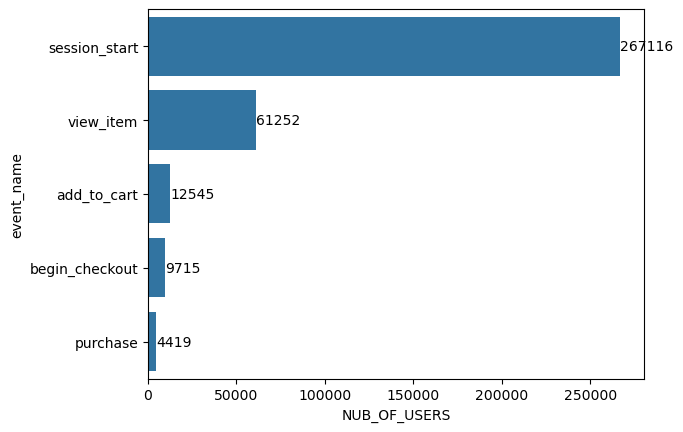

In [79]:
import matplotlib.pyplot as plt
import seaborn as sns

ax = sns.barplot(
    data=conversion,
    x="NUB_OF_USERS",
    y="event_name"
)

ax.bar_label(ax.containers[0])

plt.show()

From the conversion funnel, we found that the largest drop-off occurred between product view and add-to-cart, with approximately 80% of users dropping off at this stage. This represents a key area for further investigation.

As a next step, we could investigate potential drivers such as product relevance, pricing, product-page experience, and recommendation or search quality to understand why users who view products do not proceed to add them to their carts.

Another area worth investigating is the transition from checkout to purchase, where approximately 55% of users dropped off. Potential causes could include payment issues, unexpected costs, checkout friction, or customers simply changing their minds. Further analysis of checkout behavior could help identify the root causes and address key customer pain points.

# 4. Retention & Monetization
Do customers come back, purchase repeatedly, and generate meaningful value over time?

In [88]:
# Retention Rate
# Among new users, how many returned within 7 days after their first visit?
run_query(f"""
WITH new_acq_user AS (
SELECT user_pseudo_id,
PARSE_DATE('%Y%m%d', event_date) AS first_date
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "first_visit"
),
RETENTION AS (
SELECT user_pseudo_id,
PARSE_DATE('%Y%m%d', event_date) AS retention_date
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "session_start"
)

SELECT 
COUNT(DISTINCT P.user_pseudo_id) AS number_of_new_customer,
COUNT(DISTINCT R.user_pseudo_id) AS number_of_retainedcustomer,
ROUND(100*COUNT(DISTINCT R.user_pseudo_id)/COUNT(P.user_pseudo_id), 2) AS pct_of_retention
FROM new_acq_user P
LEFT JOIN RETENTION R ON P.user_pseudo_id = R.user_pseudo_id
AND R.retention_date > P.first_date
AND R.retention_date <= DATE_ADD(P.first_date, INTERVAL 7 DAY)
""")

Downloading: 100%|█████████████████████████████████████████████████████████████|


,number_of_new_customer,number_of_retainedcustomer,pct_of_retention
0,257314,19250,7.14


In [102]:
# Repeat Purchase Rate
run_query(f"""
WITH PURCHASED AS (
SELECT user_pseudo_id
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "purchase"
GROUP BY user_pseudo_id
),
REPURCHASE AS (
SELECT user_pseudo_id,
COUNT(DISTINCT ecommerce.transaction_id) AS PUR_TIMES
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "purchase"
GROUP BY user_pseudo_id
HAVING PUR_TIMES >= 2
)
SELECT 
COUNT(DISTINCT P.user_pseudo_id) AS number_of_purchased_customer,
COUNT(DISTINCT R.user_pseudo_id) AS number_of_repurchased_customer,
ROUND(100*COUNT(DISTINCT R.user_pseudo_id) / COUNT(DISTINCT P.user_pseudo_id), 2) AS pct_of_repurchase
FROM PURCHASED P
LEFT JOIN REPURCHASE R USING (user_pseudo_id)
""")

Downloading: 100%|█████████████████████████████████████████████████████████████|


,number_of_purchased_customer,number_of_repurchased_customer,pct_of_repurchase
0,4419,502,11.36


In [95]:
# Revenue per User
run_query(f"""
SELECT COUNT(DISTINCT user_pseudo_id) AS numb_of_users,
SUM(ecommerce.purchase_revenue) AS total_revenue,
ROUND(SUM(ecommerce.purchase_revenue) / COUNT(DISTINCT user_pseudo_id), 2) AS revenue_per_user
FROM `{DATASET}.events_*`
{DATE_RANGE} 
""")

Downloading: 100%|█████████████████████████████████████████████████████████████|


,numb_of_users,total_revenue,revenue_per_user
0,270154,362165.0,1.34


In [96]:
# AOV / Purchase Frequency
run_query(f"""
SELECT COUNT(DISTINCT ecommerce.transaction_id) AS numb_of_orders,
SUM(ecommerce.purchase_revenue) AS total_revenue,
ROUND(SUM(ecommerce.purchase_revenue) / COUNT(DISTINCT ecommerce.transaction_id), 2) AS average_order_value
FROM `{DATASET}.events_*`
{DATE_RANGE} 
""")

Downloading: 100%|█████████████████████████████████████████████████████████████|


,numb_of_orders,total_revenue,average_order_value
0,4452,362165.0,81.35


In [99]:
# purchase frequency
run_query(f"""
WITH PURCHASED_freq AS (
SELECT 
user_pseudo_id,
ecommerce.transaction_id
FROM `{DATASET}.events_*`
{DATE_RANGE} AND event_name = "purchase"
)
SELECT
COUNT(DISTINCT user_pseudo_id) AS numb_of_purchased_users,
COUNT(DISTINCT transaction_id) AS number_of_trans,
ROUND(COUNT(DISTINCT transaction_id) / COUNT(DISTINCT user_pseudo_id), 2) AS purchase_frequency
FROM PURCHASED_freq
""")

Downloading: 100%|█████████████████████████████████████████████████████████████|


,numb_of_purchased_users,number_of_trans,purchase_frequency
0,4419,4452,1.01


Based on our analysis, the 7-day retention rate is 7.14%, while 11.36% of purchasing customers made repeat purchases.

Revenue per user is \\$1.34\, while the average order value is \\$81.35\. This suggests that monetization is concentrated among a relatively small group of purchasing customers.

As a next step, we could further investigate this high-value customer segment to understand their behaviors and identify opportunities to improve customer retention and encourage repeat purchases.

# 5. Opportunity & Recommendation

Overall, the e-commerce data shows relatively strong engagement, with a 67.18% engagement rate, as well as an average order value of $81.35. However, substantial customer drop-offs throughout the conversion funnel resulted in a relatively low overall conversion rate. In addition, the low revenue per user suggests that monetization is concentrated among a relatively small group of purchasing customers.

My first priority would be to improve the conversion funnel. I would start with the largest drop-off, from product view to add-to-cart, and investigate potential drivers such as product-page experience, recommendation and search quality, pricing, and product relevance.

I would also investigate the drop-off between checkout and purchase. Since these customers have already demonstrated strong purchase intent, identifying potential friction such as payment issues, unexpected costs, or checkout experience could have a more direct impact on conversion and revenue.

Second, I would analyze the high-value customer segment to understand their purchase behaviors, purchase frequency, and product preferences. These insights could help us develop more targeted strategies to improve customer retention and encourage repeat purchases.

Third, I would further evaluate the CPC acquisition channel. Although CPC brings a smaller volume of new users compared with organic and referral channels, it generates the highest purchase conversion rate and revenue per new user. I would analyze the customer segments, campaigns, and targeting strategies behind CPC to understand whether we can scale this high-quality acquisition channel while maintaining its strong customer value.

# 6. A/B Test Design

### A/B Test Design

Based on the funnel analysis, the largest drop-off occurs between product view and add-to-cart. I propose an A/B test to evaluate whether personalized product recommendations can improve add-to-cart conversion.

The experiment would randomly assign users who view a product to either the current product detail page (Control) or a page with personalized recommendations (Treatment).

| Component | Design |
|---|---|
| **Business Problem** | Large drop-off from product view to add-to-cart |
| **Objective** | Increase add-to-cart conversion |
| **Hypothesis** | Personalized product recommendations will increase add-to-cart conversion |
| **Control** | Current product detail page |
| **Treatment** | Product detail page with personalized recommendations |
| **Target Population** | Users who view at least one product |
| **Randomization Unit** | User |
| **Primary Metric** | View Item → Add-to-Cart Conversion Rate |
| **Secondary Metric** | Purchase Conversion Rate |
| **Guardrail Metric** | Average Order Value |
| **Baseline** | 20.48% add-to-cart conversion |
| **MDE** | +2 percentage points |
| **Significance Level (α)** | 5% |
| **Statistical Power** | 80% |

In [104]:
import math
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

# A/B Test Sample Size Calculation

baseline_rate = 0.2048 # Current add-to-cart conversion rate
mde = 0.02 # Minimum Detectable Effect (MDE): +2 percentage points

# Expected treatment conversion rate
treatment_rate = baseline_rate + mde

# Statistical assumptions
alpha = 0.05
power = 0.80

# Calculate effect size
effect_size = proportion_effectsize(
    baseline_rate,
    treatment_rate)

# Calculate required sample size
analysis = NormalIndPower()

sample_size = analysis.solve_power(
    effect_size=effect_size,
    power=power,
    alpha=alpha,
    ratio=1 #ratio of control vs. treatment
)

# Round up to the nearest whole user
sample_size_per_group = math.ceil(sample_size)

total_sample_size = sample_size_per_group * 2

print("Baseline Conversion Rate:", baseline_rate)
print("Treatment Conversion Rate:", treatment_rate)
print("Required Sample Size per Group:", sample_size_per_group)
print("Total Required Sample Size:", total_sample_size)

Baseline Conversion Rate: 0.2048
Treatment Conversion Rate: 0.2248
Required Sample Size per Group: 6616
Total Required Sample Size: 13232


With a baseline conversion rate of 20.48%, an MDE of +2 percentage points, 80% power, and a 5% significance level, approximately **6,616 users per group (13,232 total)** would be required.

### Simulated A/B Test

Since the historical GA4 dataset does not contain actual experiment assignments, I simulated an A/B test based on the proposed experiment design to demonstrate the statistical evaluation process.

In [106]:
import numpy as np
np.random.seed(42)

# Sample size per group
n = 6616

# Expected conversion rates
control_rate = 0.2048
treatment_rate = 0.2248

# Simulate user-level conversion outcomes
control = np.random.binomial(
    n=1,
    p=control_rate,
    size=n
)

treatment = np.random.binomial(
    n=1,
    p=treatment_rate,
    size=n
)

# Create experiment dataset
experiment = pd.DataFrame({
    "group": ["Control"] * n + ["Treatment"] * n,
    "converted": np.concatenate([control, treatment])
})

# Summarize results
experiment_summary = (
    experiment
    .groupby("group")["converted"]
    .agg(
        users="count",
        conversions="sum",
        conversion_rate="mean"
    )
)

experiment_summary["conversion_rate"] *= 100

display(experiment_summary)

,users,conversions,conversion_rate
group,,,
Control,6616,1357,20.510883
Treatment,6616,1456,22.007255


In [107]:
from statsmodels.stats.proportion import proportions_ztest
# Two-Proportion Z-Test

# Number of conversions in each group
control_conversions = control.sum()
treatment_conversions = treatment.sum()

# Number of users in each group
control_users = len(control)
treatment_users = len(treatment)

# Prepare inputs for the z-test
conversions = [
    control_conversions,
    treatment_conversions
]

users = [
    control_users,
    treatment_users
]

# Run two-proportion z-test
z_stat, p_value = proportions_ztest(
    count=conversions,
    nobs=users,
    alternative="two-sided"
)

print("Control Conversion Rate:", round(control_conversions / control_users * 100, 2), "%")

print("Treatment Conversion Rate:", round(treatment_conversions / treatment_users * 100, 2), "%")

print("Z-statistic:", round(z_stat, 3))
print("P-value:", round(p_value, 4))

Control Conversion Rate: 20.51 %
Treatment Conversion Rate: 22.01 %
Z-statistic: -2.104
P-value: 0.0354


In [108]:
from scipy.stats import norm

# 95% Confidence Interval for Conversion Rate Difference

control_rate_observed = control.mean()
treatment_rate_observed = treatment.mean()

# Observed difference
absolute_lift = treatment_rate_observed - control_rate_observed

# Standard error
standard_error = np.sqrt(
    control_rate_observed * (1 - control_rate_observed) / len(control)
    +
    treatment_rate_observed * (1 - treatment_rate_observed) / len(treatment)
)

# Critical value for 95% confidence
z_critical = norm.ppf(0.975)

# Confidence interval
ci_lower = absolute_lift - z_critical * standard_error
ci_upper = absolute_lift + z_critical * standard_error

print("Absolute Lift:",
      round(absolute_lift * 100, 2), "percentage points")

print("Relative Lift:",
      round(absolute_lift / control_rate_observed * 100, 2), "%")

print(
    "95% Confidence Interval:",
    f"[{ci_lower * 100:.2f}, {ci_upper * 100:.2f}] percentage points"
)

Absolute Lift: 1.5 percentage points
Relative Lift: 7.3 %
95% Confidence Interval: [0.10, 2.89] percentage points


The simulated A/B test showed that personalized product recommendations increased add-to-cart conversion from 20.51% to 22.01%, representing a 1.50 percentage-point lift. The result was statistically significant (p = 0.0354, 95% CI: [0.10, 2.89] pp).

However, the observed lift was below the predefined 2 percentage-point MDE. Therefore, while the treatment showed a positive effect, its business impact should be further evaluated before a full rollout.